# Search: Solving a Maze Using a Goal-based Agent

Student Name: Ngo Dong At

I have used the following AI tools: Claude (Anthropic) – hỗ trợ viết/kiểm thử code và soạn nhận xét; tôi đã đọc lại, chạy lại và kiểm tra kết quả

I understand that my submission needs to be my own work: [your initials]

## Learning Outcomes

* Formulate search problems using key components like initial state, actions, and goal state in a deterministic, fully observable environment.
* Implement the search algorithm BFS for planning paths through mazes.
* Use visualization tools to represent maze paths and support debugging and analysis.

## Instructions

Total Points: Undergrads 10

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the notebook file and the completely rendered notebook with all outputs as a HTML file. 


## Introduction

In this exercise, we will implement the planning function for a type of goal-based agent called a __planning agent__. The planning function uses a map it is given to plan a path through the maze from the starting location $S$ to the goal location $G$. We will only focus on the planning function, so you do not need to implement an environment, just use the map to search for a path to solve the maze. 

Once the plan is made, the agent in a deterministic environment (i.e., the transition function is deterministic with the outcome of each state/action pair fixed and no randomness) can just follow the plan step-by-step and does not need to care about the percepts.
This is also called an **[open-loop system](https://en.wikipedia.org/wiki/Open-loop_controller).**
The execution phase is trivial and can be executed using a model-based reflex agent 
that ignores all percepts and just follows the plan. I will show you a short example, but you do not implement it in this exercise.

Given that the agent has a complete and correct map, the environment is **fully observable, discrete, deterministic, and known.** 
Remember:

* **Fully observable** means that the agent can see its state and what the available actions are. That means the **percepts contain the complete current state.**
Here, during planning, the agent always sees its x and y coordinates on the map and
also seeks when it has reached the goal state. 
* **Discrete** means that we have a **finite set of states.** The maze has a finite set 
of squares the agent can be in.
* **Deterministic** means that the **transition function contains no randomness.** An action in a state will always produce the same result. Going south from the start state always will lead to the same square.
* **Know** means that the agent **knows the complete transition function.** The 
agent has the map and therefore knows how its position changes when it walks in a direction.

Tree search algorithm implementations that you find online typically come from data structures courses and have a different aim than AI tree search. These algorithms assume that you already have a tree in memory. We are interested in dynamically creating a search tree with the aim of finding a good/the best path from the root note to the goal state. Follow the pseudo code presented in the text book (and replicated in the slides) closely. Ideally, we would like to search only a small part of the maze, i.e., create a search tree with as few nodes as possible. 

Several mazes for this exercise are stored as text files. We need to make sure that they are locally available.

In [1]:
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

base_url = "https://raw.githubusercontent.com/mhahsler/Introduction_to_Artificial_Intelligence/refs/heads/master/Search/"
download("maze_helper.py", base_url)

mazes = ["small_maze.txt", "large_maze.txt", "open_maze.txt", "empty_maze.txt"]
for maze in mazes:
    download(maze, base_url)

Here is the small example maze:

In [2]:
with open("small_maze.txt", "r") as f:
    maze_str = f.read()
print(maze_str)

XXXXXXXXXXXXXXXXXXXXXX
X XX        X X      X
X    XXXXXX X XXXXXX X
XXXXXX     S  X      X
X    X XXXXXX XX XXXXX
X XXXX X         X   X
X        XXX XXX   X X
XXXXXXXXXX    XXXXXX X
XG         XX        X
XXXXXXXXXXXXXXXXXXXXXX



**Note:** If you get an error here that the file cannot be found, then you need to download it. See [HOWTO Work on Assignments.](https://github.com/mhahsler/CS7320-AI/blob/master/HOWTOs/working_on_assignments.md)

## Parsing and pretty printing the maze

The maze can also be displayed in color using code in the module [maze_helper.py](maze_helper.py). The code parses the string representing the maze and converts it into a `numpy` 2d array which you can use in your implementation. Position are represented as a 2-tuple of the form `(row, col)`. 

In [3]:
import maze_helper as mh

maze = mh.parse_maze(maze_str)

# look at a position in the maze by subsetting the 2d array
print("Position(0,0):", maze[0, 0])

# there is also a helper function called `look(maze, pos)` available
# which uses a 2-tuple for the position.
print("Position(8,1):", mh.look(maze, (8, 1)))

Position(0,0): X
Position(8,1): G


A helper function to visualize the maze is also available.

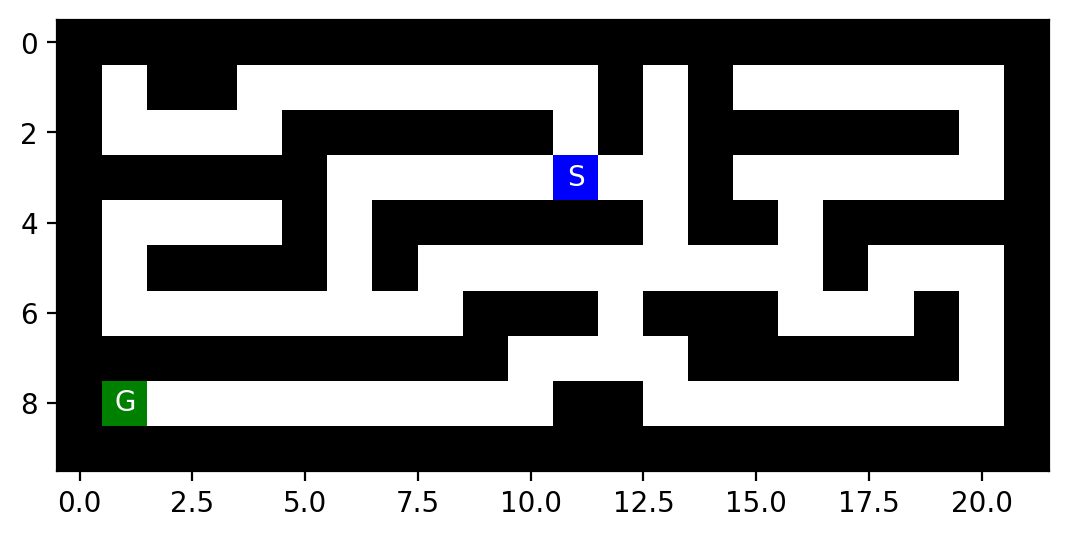

In [4]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
# use higher resolution images in notebooks

mh.show_maze(maze)

Find the `(x,y)` position of the start and the goal using the helper function `find_pos()`

In [5]:
print("Start location:", mh.find_pos(maze, what = "S"))
print("Goal location:", mh.find_pos(maze, what = "G"))

Start location: (np.int64(3), np.int64(11))
Goal location: (np.int64(8), np.int64(1))


Helper function documentation.

In [6]:
help(mh)

Help on module maze_helper:

NAME
    maze_helper

DESCRIPTION
    Code for the Maze Assignment
    Usage:
        import maze_helper as mh
        mh.show_some_mazes()

FUNCTIONS
    animate_maze(result, repeat=False)
        (Experimental) Build an animation from a list of mazes.

        Parameters:
            result: a list with the elements path, reached, actions and maze_anim with a list of maze arrays that contain what you want to visualize.
            repeat: if True, the animation will repeat.

    find_pos(maze, what='S')
        Find start/goal in a maze and returns the first one.
        Caution: there is no error checking!

        Parameters:
            maze: a array with characters produced by parse_maze()
            what: the letter to be found ('S' for start and 'G' for goal)

        Returns:
            a tupple (x, y) for the found position.

    look(maze, pos)
        Look at the label of a square with the position as an array of the form (x, y).

        Para

You will need to make a local copy of the module file [maze_helper.py](maze_helper.py) in the same folder where your notebook is.

## An Example for a Planning Agent

I will show you here how to implement a simple agent that uses a random plan. It will not solve the maze, but show you how the mechanics work.

First, we define a generic planning agent that fist plans, and then executes the plan step-by-step. 

In [7]:
class Planning_Agent:
    def __init__(self, maze, start, goal, planning_function):
        self.maze = maze
        self.start = start
        self.goal = goal
        self.planning_function = planning_function
        self.plan = None
        self.progress = None

    def act(self):
        # plan if no plan exists
        if self.plan is None:
            print("Planning...")
            self.plan = self.planning_function(self.maze, self.start, self.goal)
            self.progress = 0
        
        # check if plan is completed
        if self.progress >= len(self.plan):        
            raise Exception("Completed Plan. No more planned actions")
        
        # follow the plan
        action = self.plan[self.progress]
        print(f"Following plan... step {self.progress}: {action}")

        self.progress += 1
        return action

Next, we define the planning function. This function is what you will implement in this assignment.  

In [8]:
import numpy as np

def plan_random(maze, start, goal):
    """Create a random plan with 10 steps"""
    plan = np.random.choice(["N", "E", "S", "W"], size=10, replace=True).tolist()
    return plan

plan_random(maze, (1,1), (8,8))

['S', 'E', 'S', 'N', 'W', 'N', 'N', 'W', 'S', 'N']

This planning function is not great and will not produce a plan that solves the maze. Your planning functions will do better.

Finally, we can create the planning agent, give it the planning function and implement a simple environment that asks it 11 times for an action.

In [9]:
my_agent = Planning_Agent(maze, mh.find_pos(maze, what = "S"), mh.find_pos(maze, what = "G"), plan_random)

def environment(agent_function, steps):
    for _ in range(steps):
        try:
            agent_function()
        except Exception as e:
            print(f"Agent exception: {e}")

environment(my_agent.act, steps=11)

Planning...
Following plan... step 0: E
Following plan... step 1: E
Following plan... step 2: E
Following plan... step 3: S
Following plan... step 4: N
Following plan... step 5: N
Following plan... step 6: E
Following plan... step 7: W
Following plan... step 8: E
Following plan... step 9: E
Agent exception: Completed Plan. No more planned actions


Note: The agent and environment implementation above is just an illustration. You will only implement and experiment with different versions of the planning function.

## Tree structure

To use tree search, you will need to implement a tree data structure in Python. 
Here is an implementation of the basic node structure for the search algorithms (see Fig 3.7 on page 73). I have added a method that extracts the path from the root node to the current node. It can be used to get the path when the search is completed.

In [10]:
class Node:
    def __init__(self, pos, parent, action, cost):
        self.pos = tuple(pos)    # the state; positions are (row,col)
        self.parent = parent     # reference to parent node. None means root node.
        self.action = action     # action used in the transition function (root node has None)
        self.cost = cost         # for uniform cost this is the depth. It is also g(n) for A* search

    def __str__(self):
        return f"Node - pos = {self.pos}; action = {self.action}; cost = {self.cost}"
    
    def get_path_from_root(self):
        """returns nodes on the path from the root to the current node."""
        node = self
        path = [node]
    
        while not node.parent is None:
            node = node.parent
            path.append(node)
        
        path.reverse()
        
        return(path)

If needed, then you can add more fields to the class like the heuristic value $h(n)$ or $f(n)$.

Examples for how to create and use a tree and information on memory management can be found [here](../HOWTOs/trees.ipynb).

# Tasks

The goal is to:

1. Implement the following search algorithm for solving different mazes:
    - Breadth-first search (BFS)

2. Run each of the above algorithms on the 
    - [small maze](small_maze.txt), 
    - [large maze](large_maze.txt), 
    - [open maze](open_maze.txt), and
    - [empty maze](empty_maze.txt).

3. Display each solution by marking every maze square (or state) visited and the squares on the final path.

## General

1. Make sure that you use the latest version of this notebook.
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally. 
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.

## Task 1: Defining the search problem and determining the problem size [2 Points]

Define the components of the search problem:

* Initial state
* Actions
* Transition model
* Goal state
* Path cost

Use verbal descriptions, variables and equations as appropriate. 

*Note:* You can switch the next block from code to Markdown and use formatting.

### Định nghĩa bài toán tìm kiếm (mê cung)

| Thành phần | Định nghĩa |
|---|---|
| **Trạng thái** | Vị trí của tác tử $s=(r,c)$ (hàng, cột) trên một ô *không phải tường*. |
| **Trạng thái đầu** | $s_0$ = vị trí ô `S`. |
| **Hành động** | $ACTIONS(s)\subseteq\{N,E,S,W\}$: các hướng mà ô kế tiếp không phải tường `X` (và không ra ngoài bản đồ). |
| **Mô hình chuyển trạng thái** | $RESULT((r,c),a)=(r+\Delta r,\,c+\Delta c)$ với $\Delta_N=(-1,0)$, $\Delta_E=(0,1)$, $\Delta_S=(1,0)$, $\Delta_W=(0,-1)$. Xác định (không ngẫu nhiên) nên kế hoạch có thể chạy "mở vòng" (open-loop). |
| **Trạng thái đích** | $GOAL\text{-}TEST(s)$ đúng khi $s$ là ô `G` (với bài toán nhiều đích: $s\in\mathcal G$, tập các ô `G`). |
| **Chi phí đường đi** | Mỗi bước có chi phí $c(s,a,s')=1$, nên $g(n)=$ số bước từ gốc $=$ độ sâu của nút. Lời giải tối ưu là đường đi ngắn nhất. |

Trong code: `valid_actions(maze, pos)` cài $ACTIONS(s)$, cặp (`ACTIONS[a]`, cộng vào vị trí) cài $RESULT(s,a)$, và `child.pos == goal` là goal-test.

Give some estimates for the problem size:

* $d$: depth of the optimal solution
* $m$: maximum depth of tree
* $b$: maximum branching factor

Describe how you would determine these values for a given maze.

* **$d$ – độ sâu của lời giải tối ưu** $=$ số bước của đường đi ngắn nhất từ `S` tới `G`. Chặn dưới: khoảng cách Manhattan $|r_S-r_G|+|c_S-c_G|$; giá trị chính xác lấy từ chi phí lời giải của BFS (vd. small: $d=19$, chặn dưới 15).
* **$m$ – độ sâu tối đa của cây tìm kiếm.** Với BFS dùng `reached` thì độ sâu lớn nhất của cây $=d$ (BFS dừng ngay khi sinh ra nút đích ở độ sâu $d$). Nếu không chống lặp trạng thái thì cây vô hạn ($m=\infty$); nếu chỉ chống chu trình thì $m\le n$, với $n$ là số ô trống.
* **$b$ – hệ số phân nhánh tối đa** $=\max_s|ACTIONS(s)|=4$ (ô trống bốn phía). Sau khi loại hướng quay lại nút cha còn tối đa 3 con; trong hành lang hẹp thì $b\approx 1$–2.

**Cách xác định cho một mê cung bất kỳ:** đếm hướng đi hợp lệ của mọi ô trống để có $b$; chạy BFS để lấy $d$ (số bước của lời giải) và độ sâu lớn nhất đã sinh ra ($m$ của cây BFS); số ô trống `(maze != 'X').sum()` cho biết $n$ – cũng là chặn trên số nút mà BFS với `reached` phải mở rộng.

## Task 2: Breadth-First Search [5 Points]

Implement this simple search strategies. Follow the pseudocode in the textbook/slides. You can use the tree structure shown above to extract the final path from your solution.

Read the following **important note** carefully:
* You can find maze solving implementations online that use the map to store information. While this is an effective idea for this two-dimensional navigation problem, it typically cannot be used for other search problems. Therefore, follow the textbook and **do not store information in the map.** Only store information in the tree created during search, and use the `reached` and `frontier` data structures where appropriate.


In [11]:
# ---------- BFS cho mê cung (tree search + reached, goal-test khi sinh nút) ----------
import numpy as np
from collections import deque

# Hành động -> độ dịch chuyển (row, col). Chi phí mỗi bước = 1.
ACTIONS = {"N": (-1, 0), "E": (0, 1), "S": (1, 0), "W": (0, -1)}

def valid_actions(maze, pos):
    """ACTIONS(s): các hướng không dẫn vào tường 'X' hoặc ra ngoài bản đồ."""
    r, c = pos
    return [a for a, (dr, dc) in ACTIONS.items()
            if 0 <= r + dr < maze.shape[0] and 0 <= c + dc < maze.shape[1]
            and maze[r + dr, c + dc] != "X"]

def bfs(maze, start, goal, order="NESW"):
    """Trả về dict: actions (kế hoạch), path (các ô), cost, expanded, explored.
    Chỉ lưu thông tin trong cây (Node), `reached` và `frontier` - KHÔNG ghi vào bản đồ."""
    start, goal = tuple(start), tuple(goal)
    root = Node(start, None, None, 0)
    if root.pos == goal:
        return dict(actions=[], path=[start], cost=0, expanded=0, explored=[])

    frontier = deque([root])              # hàng đợi FIFO
    reached = {start}                     # các trạng thái đã gặp (tránh lặp trạng thái)
    explored, expanded = [], 0
    while frontier:
        node = frontier.popleft()
        expanded += 1
        explored.append(node.pos)
        ok = valid_actions(maze, node.pos)
        for a in order:                   # mô hình chuyển trạng thái: RESULT(s, a)
            if a not in ok:
                continue
            dr, dc = ACTIONS[a]
            child = Node((node.pos[0] + dr, node.pos[1] + dc), node, a, node.cost + 1)
            if child.pos == goal:         # kiểm tra đích ngay khi sinh nút
                nodes = child.get_path_from_root()
                return dict(actions=[n.action for n in nodes[1:]], path=[n.pos for n in nodes],
                            cost=child.cost, expanded=expanded, explored=explored)
            if child.pos not in reached:
                reached.add(child.pos)
                frontier.append(child)
    return None                           # không có lời giải

def plan_bfs(maze, start, goal):
    """Hàm lập kế hoạch cho Planning_Agent: trả về dãy hành động."""
    result_ = bfs(maze, start, goal)
    return None if result_ is None else result_["actions"]

The result of the planning function is a sequence of actions. Fill out the following table:


| maze | path length | # of nodes expanded |
|-----------|-----------|------------------|
| small     | 19 | 90 |
| large     | 210 | 618 |
| open      | 54 | 679 |
| empty     | 14 | 92 |

*(path length = số bước của kế hoạch; BFS mở rộng gần như mọi ô nằm trong "bán kính" $d$ nên số nút mở rộng xấp xỉ số ô trống: small 94 ô, large 647 ô, open 684 ô, empty 100 ô.)*

Visualize the found path for each maze. You can look at the `show_maze()` function in [maze_helper.py](maze_helper.py) to see how you can visualize the path.

 maze  path length  # of nodes expanded
small           19                   90
large          210                  618
 open           54                  679
empty           14                   92
small: kế hoạch dài 19 bước, mở rộng 90 nút


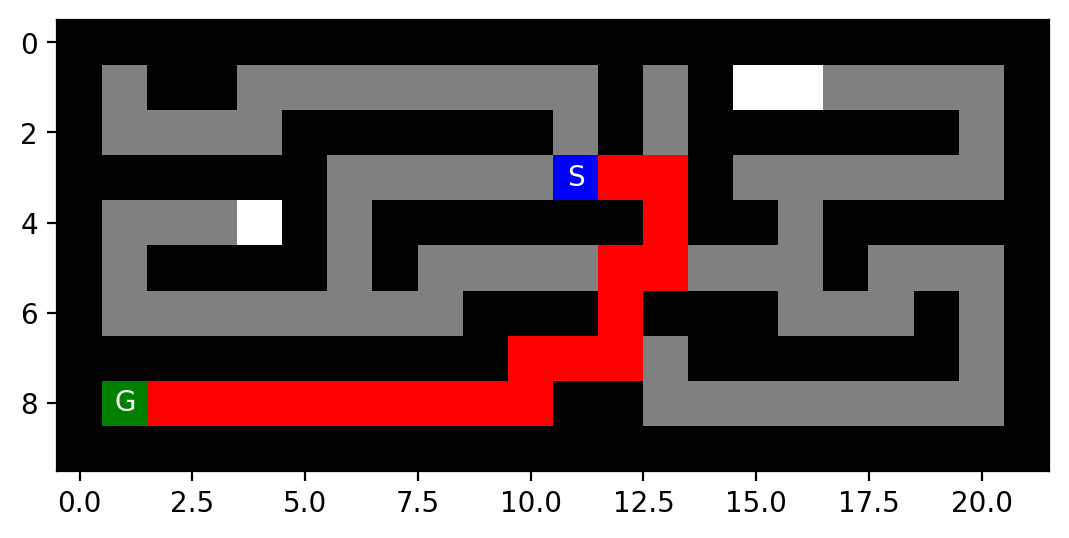

large: kế hoạch dài 210 bước, mở rộng 618 nút


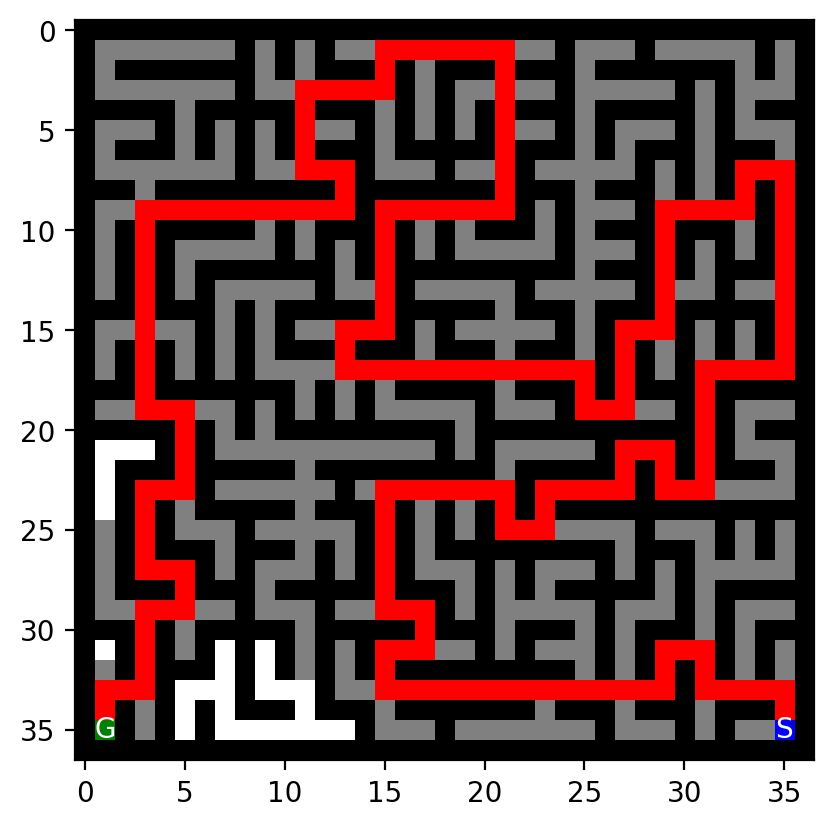

open: kế hoạch dài 54 bước, mở rộng 679 nút


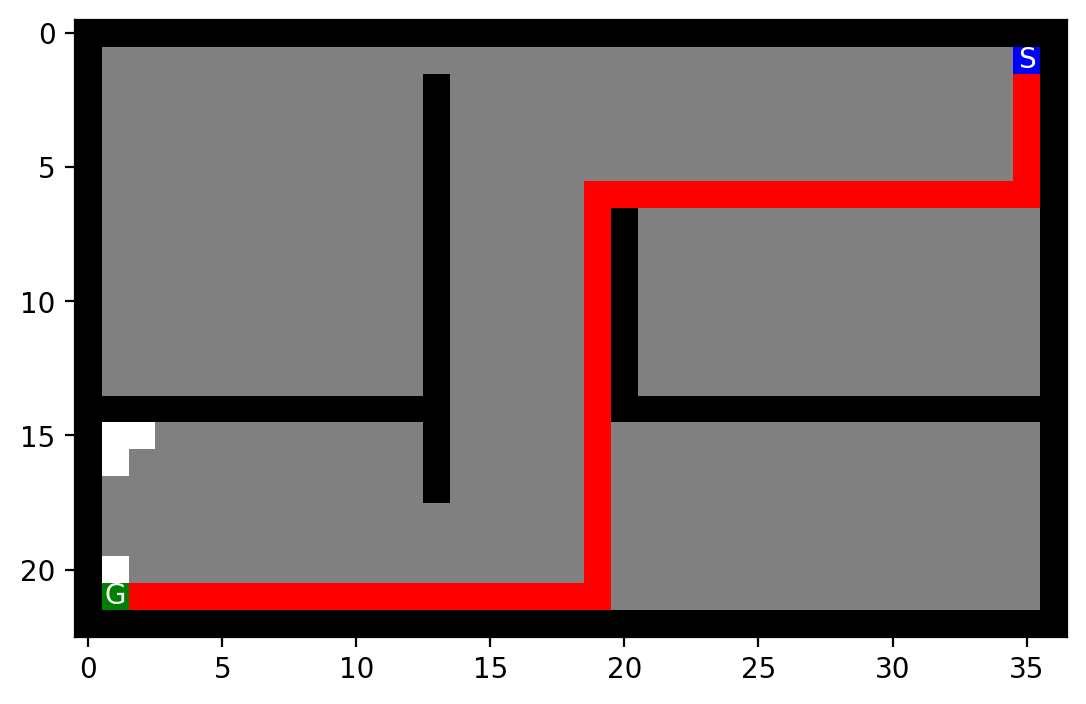

empty: kế hoạch dài 14 bước, mở rộng 92 nút


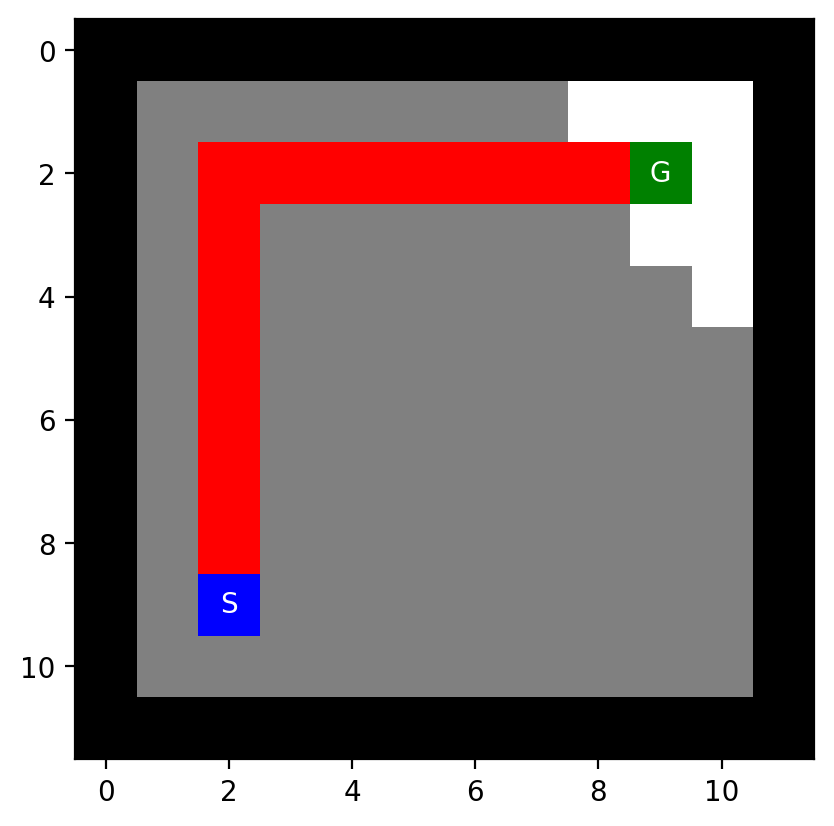

In [12]:
import pandas as pd
import matplotlib.pyplot as plt

MAZES = {"small": "small_maze.txt", "large": "large_maze.txt",
         "open": "open_maze.txt", "empty": "empty_maze.txt"}

def load_maze(name):
    with open(MAZES[name], "r") as f:
        maze = mh.parse_maze(f.read())
    return maze, tuple(int(v) for v in mh.find_pos(maze, "S")), tuple(int(v) for v in mh.find_pos(maze, "G"))

def mark_path(maze, res):
    """Bản sao để VẼ: '.' = ô đã mở rộng, 'P' = đường đi cuối (không sửa bản đồ gốc)."""
    m = maze.copy()
    for p in res["explored"]:
        if m[p] == " ": m[p] = "."
    for p in res["path"][1:-1]:
        m[p] = "P"
    return m

rows, results = [], {}
for name in MAZES:
    maze, start, goal = load_maze(name)
    res = bfs(maze, start, goal)
    results[name] = (maze, res)
    rows.append({"maze": name, "path length": res["cost"], "# of nodes expanded": res["expanded"]})
table = pd.DataFrame(rows)
print(table.to_string(index=False))

# Hiển thị đường đi + vùng đã mở rộng (xám) cho từng mê cung bằng hàm có sẵn của maze_helper
for name, (maze, res) in results.items():
    print(f"{name}: kế hoạch dài {res['cost']} bước, mở rộng {res['expanded']} nút")
    mh.show_maze(mark_path(maze, res))

In [13]:
# ---- Lưu bảng kết quả và hình ra thư mục results_ex2/ ----
import matplotlib
import os
os.makedirs("results_ex2", exist_ok=True)
table.to_csv("results_ex2/bfs_bang_ket_qua.csv", index=False, encoding="utf-8-sig")
try:
    table.to_excel("results_ex2/bfs_bang_ket_qua.xlsx", index=False)
except ImportError:
    pass

for name, (maze, res) in results.items():
    fig, ax = plt.subplots(figsize=(6, 6))
    cmap = matplotlib.colors.ListedColormap(["white", "black", "blue", "green", "red", "gray", "orange"])
    code = {" ": 0, "X": 1, "S": 2, "G": 3, "P": 4, ".": 5, "F": 6}
    m = mark_path(maze, res)
    ax.imshow(np.array([[code[ch] for ch in row] for row in m]), cmap=cmap,
              norm=matplotlib.colors.BoundaryNorm(range(8), 7))
    for label in "SG":
        r, c = np.argwhere(m == label)[0]
        ax.text(c, r, label, color="white", ha="center", va="center")
    ax.set_title(f"BFS - {name} maze: {res['cost']} bước, mở rộng {res['expanded']} nút")
    ax.set_xticks([]); ax.set_yticks([])
    fig.savefig(f"results_ex2/bfs_{name}.png", dpi=150, bbox_inches="tight")
    plt.close(fig)
print("Đã lưu:", sorted(os.listdir("results_ex2")))

Đã lưu: ['bfs_bang_ket_qua.csv', 'bfs_bang_ket_qua.xlsx', 'bfs_empty.png', 'bfs_large.png', 'bfs_open.png', 'bfs_small.png']


# Task 3: Discussion [3 Points] 

Is your implementation complete and optimal? Explain why. What is the time and space complexity of each of **your** implementation?

**Đầy đủ và tối ưu.** BFS **đầy đủ** vì không gian trạng thái hữu hạn và `reached` ngăn lặp trạng thái nên cây hữu hạn: nếu có đường đi từ `S` tới `G` thì nút ở độ sâu $d$ chắc chắn được sinh ra. BFS **tối ưu** vì chi phí mỗi bước bằng 1: các nút được lấy theo thứ tự độ sâu tăng dần, nên nút đích đầu tiên được sinh ra có độ sâu (chi phí) nhỏ nhất. Kiểm tra đích khi *sinh* nút vẫn đúng với chi phí đều, và tiết kiệm được một tầng.

**Độ phức tạp.** Thời gian $O(b^d)$ trong cây tìm kiếm, nhưng nhờ `reached` mỗi ô chỉ được mở rộng một lần nên tổng cộng $O(n)$ (đồng thời $O(b^d)$ là chặn trên). Bộ nhớ $O(b^d)$ / $O(n)$ vì phải giữ toàn bộ biên (`frontier`) và `reached`. Số liệu thực tế: small 90, large 618, open 679, empty 92 nút được mở rộng – gần bằng số ô trống ở bán kính $d$.

How would the planning improve if you use informed search with A* search and the Euclidean distance to the goal as the heuristic? What would the algorithm do differently?

A\* dùng $f(n)=g(n)+h(n)$ với $h$ là khoảng cách Euclid tới đích. $h$ này *admissible* (đường thẳng không bao giờ dài hơn đường đi 4 hướng thực) và consistent nên A\* vẫn **tối ưu**, nhưng thứ tự mở rộng khác BFS: thay vì lan đều theo vòng tròn quanh `S`, A\* ưu tiên nút có $f$ nhỏ nhất, tức hướng về phía `G`, nên mở rộng ít nút hơn ở không gian mở: theo thử nghiệm ở Ex1, A\*-Euclid mở rộng 55 nút ở small (BFS 90), 516 ở open (BFS 679), 61 ở empty (BFS 92). Ở mê cung hành lang như large lợi ích rất ít (554 so với 618) vì tường làm khoảng cách Euclid kém chính xác. Dùng Manhattan còn tốt hơn: $h$ sát chi phí thật hơn nên A\* mở rộng 211 nút ở open và 14 ở empty. Đổi lại A\* cần thêm hàng đợi ưu tiên và phép tính $h$ cho mỗi nút (chi phí $O(\log|frontier|)$ mỗi thao tác).

Your BFS implementation works fine to solve small mazes. Why would it not work for larger problems with millions of states and 100s of actions? What algorithm could be used then?

Với hàng triệu trạng thái và hàng trăm hành động ($b\approx100$), số nút BFS phải giữ trong bộ nhớ là $O(b^d)$ – chẳng hạn $100^5=10^{10}$ chỉ với $d=5$ – vượt xa RAM, và thời gian cũng tăng theo hàm mũ; ngoài ra phải lưu cả `reached` cho mọi trạng thái. Khi đó có thể dùng: **A\* với heuristic tốt** (hoặc Weighted A\*) để thu hẹp vùng cần duyệt; **IDA\*** hay **IDS** để bộ nhớ chỉ còn tuyến tính theo độ sâu $O(bd)$; **tìm kiếm hai chiều** (giảm $b^d$ còn $\approx 2\,b^{d/2}$); **SMA\*/beam search** khi giới hạn bộ nhớ; hoặc đổi cách biểu diễn (trạng thái trừu tượng, planning phân cấp, **local search**) nếu không cần lời giải tối ưu tuyệt đối.